# Lecture 1: Geometry of Data & Variance

## Mathematics for Machine Learning

### Topics Covered
- Data as points in n-dimensional space
- Mean & variance
- Standard deviation
- Sample vs population
- Variance as information
- Visualizing clusters

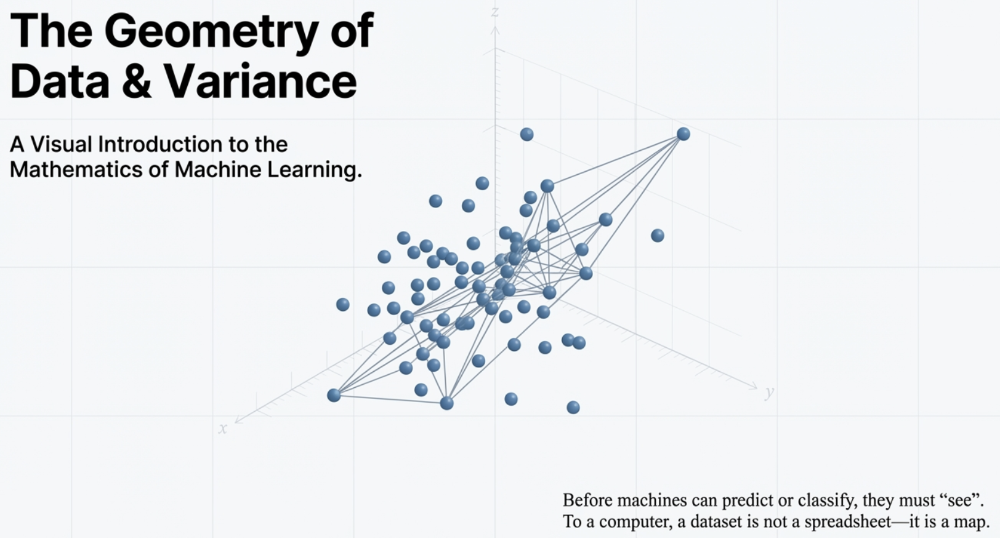

---

## Introduction

Before machine learning algorithms can classify fish, predict IPL match outcomes, or recommend T-shirt sizes, they need to understand data. But what does it mean to *understand* data?

Think about how you recognize patterns:
- You know your friends by their height, voice, style
- You distinguish fruits by color, size, texture
- You group similar things together naturally

Machine learning does the same thing, but mathematically. Today we'll discover how data lives in geometric space and how we measure its spread and clustering.

### What You'll Learn

By the end of this lecture, you'll understand:
1. How every dataset is a collection of points in multi-dimensional space
2. What the "center" of data really means
3. How spread (variance) tells us about information content
4. Why some datasets are easier to separate than others
5. The geometric foundation that makes ML algorithms work

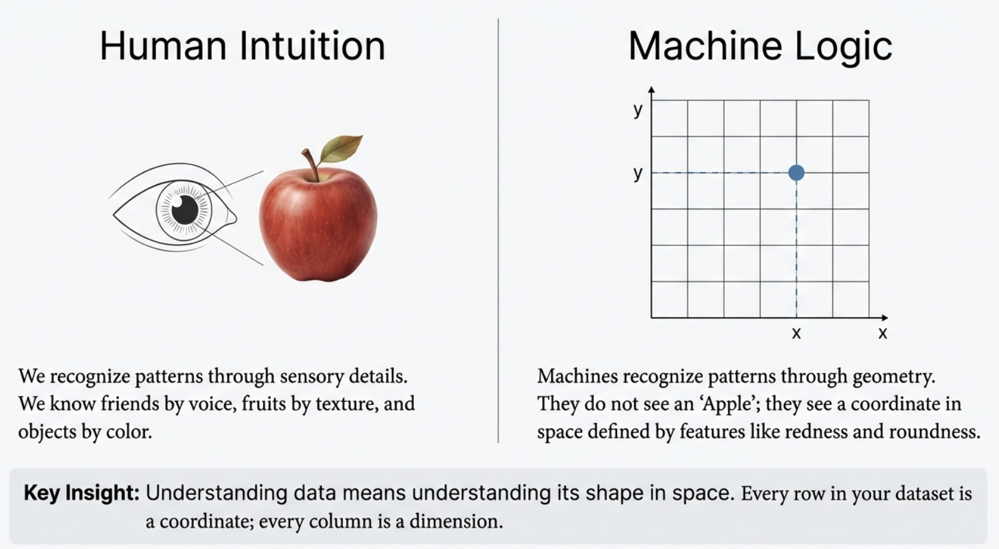

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Set random seed for reproducibility
np.random.seed(42)

---

## Part 1: Data as Points in Space

### The One-Dimensional World

Let's start simple. Imagine measuring just the height of students in a class.

In [ ]:
# Heights of 20 students (in cm)
heights = np.array([165, 170, 168, 172, 169, 171, 167, 173, 170, 166,
                    169, 171, 168, 170, 172, 167, 169, 171, 170, 168])

print(f"Number of students: {len(heights)}")
print(f"Heights: {heights}")

Number of students: 20
Heights: [165 170 168 172 169 171 167 173 170 166 169 171 168 170 172 167 169 171
 170 168]


Each height is a **data point**. In one dimension, we can visualize these points on a number line:

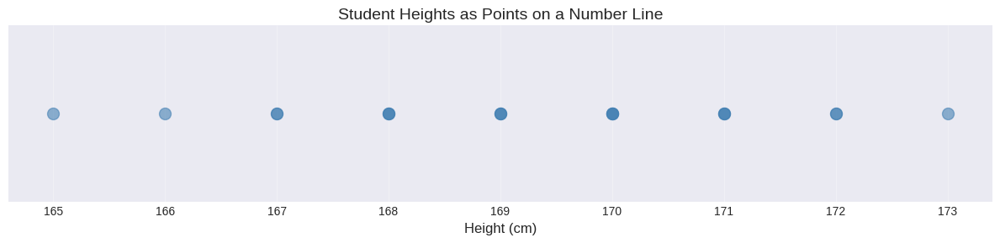


Observation: Each student is represented by a single point in 1D space.


In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))

# Plot each height as a point on a line
ax.scatter(heights, np.zeros_like(heights), s=100, alpha=0.6, c='steelblue')
ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_yticks([])
ax.set_title('Student Heights as Points on a Number Line', fontsize=14)
ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nObservation: Each student is represented by a single point in 1D space.")

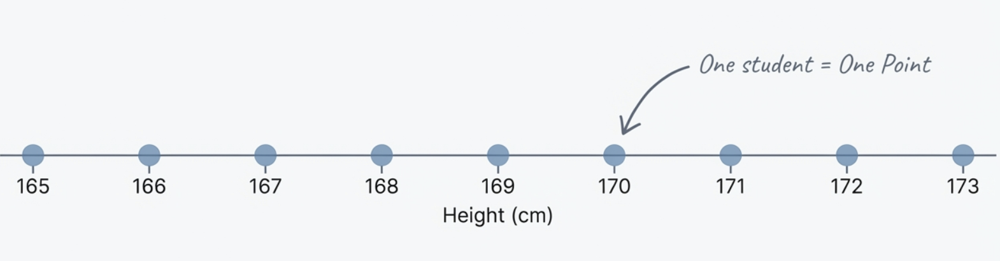

### The Two-Dimensional World

Now suppose we measure both height and weight. Each student is now described by **two features**.

In [ ]:
# Add weights (in kg) for the same students
weights = np.array([62, 68, 65, 70, 67, 69, 64, 72, 68, 63,
                    67, 69, 66, 68, 71, 64, 67, 70, 68, 65])

print(f"Student 1: Height = {heights[0]} cm, Weight = {weights[0]} kg")
print(f"Student 2: Height = {heights[1]} cm, Weight = {weights[1]} kg")
print(f"Student 3: Height = {heights[2]} cm, Weight = {weights[2]} kg")

Student 1: Height = 165 cm, Weight = 62 kg
Student 2: Height = 170 cm, Weight = 68 kg
Student 3: Height = 168 cm, Weight = 65 kg


Each student is now a point in **2D space** with coordinates (height, weight):

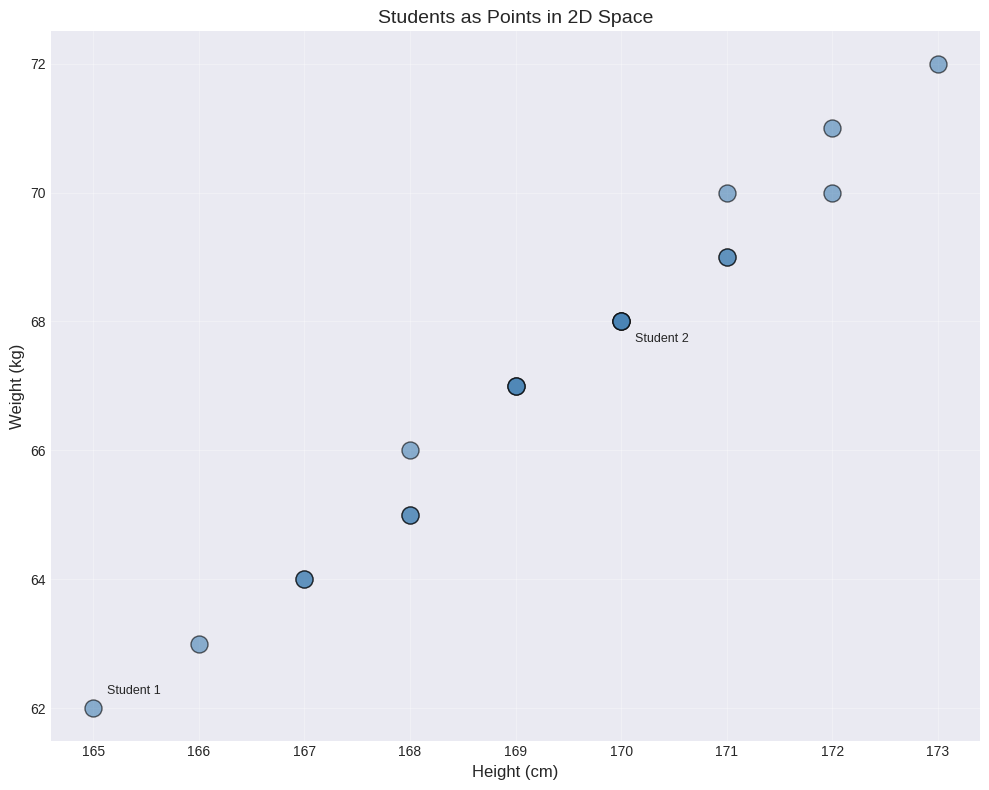


Key Insight: Moving from 1D to 2D, each student becomes a point in a plane.
The position of the point encodes both features simultaneously.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(heights, weights, s=150, alpha=0.6, c='steelblue', edgecolors='black')
ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_title('Students as Points in 2D Space', fontsize=14)
ax.grid(True, alpha=0.3)

# Annotate a few points
ax.annotate('Student 1', (heights[0], weights[0]),
            xytext=(10, 10), textcoords='offset points', fontsize=9)
ax.annotate('Student 2', (heights[1], weights[1]),
            xytext=(10, -15), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

print("\nKey Insight: Moving from 1D to 2D, each student becomes a point in a plane.")
print("The position of the point encodes both features simultaneously.")

### The Three-Dimensional World

What if we add a third measurement—age?

In [ ]:
# Add ages (in years)
ages = np.array([20, 22, 21, 23, 21, 22, 20, 24, 22, 21,
                 21, 22, 21, 22, 23, 20, 21, 23, 22, 21])

print(f"Student 1: Height = {heights[0]} cm, Weight = {weights[0]} kg, Age = {ages[0]} yrs")
print(f"Student 2: Height = {heights[1]} cm, Weight = {weights[1]} kg, Age = {ages[1]} yrs")

Student 1: Height = 165 cm, Weight = 62 kg, Age = 20 yrs
Student 2: Height = 170 cm, Weight = 68 kg, Age = 22 yrs


Now each student is a point in **3D space** with coordinates (height, weight, age):

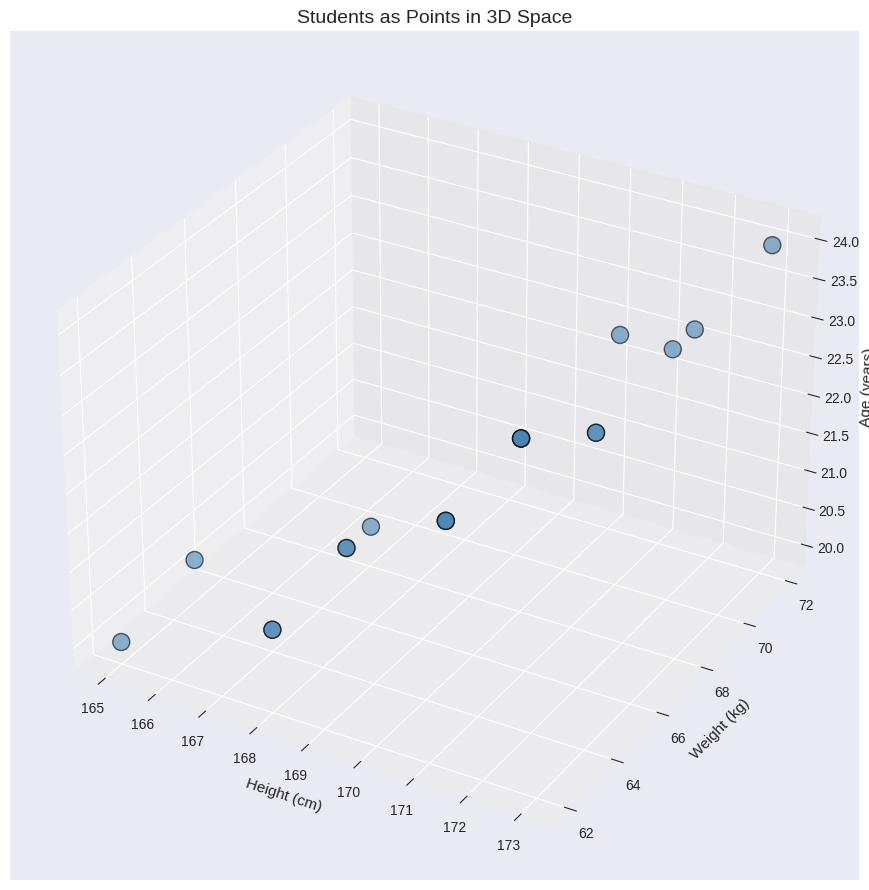


Pattern: As we add features, our data exists in higher dimensions.
Each dimension corresponds to one feature.


In [ ]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(heights, weights, ages, s=150, alpha=0.6, c='steelblue', edgecolors='black')
ax.set_xlabel('Height (cm)', fontsize=11)
ax.set_ylabel('Weight (kg)', fontsize=11)
ax.set_zlabel('Age (years)', fontsize=11)
ax.set_title('Students as Points in 3D Space', fontsize=14)

plt.tight_layout()
plt.show()

print("\nPattern: As we add features, our data exists in higher dimensions.")
print("Each dimension corresponds to one feature.")

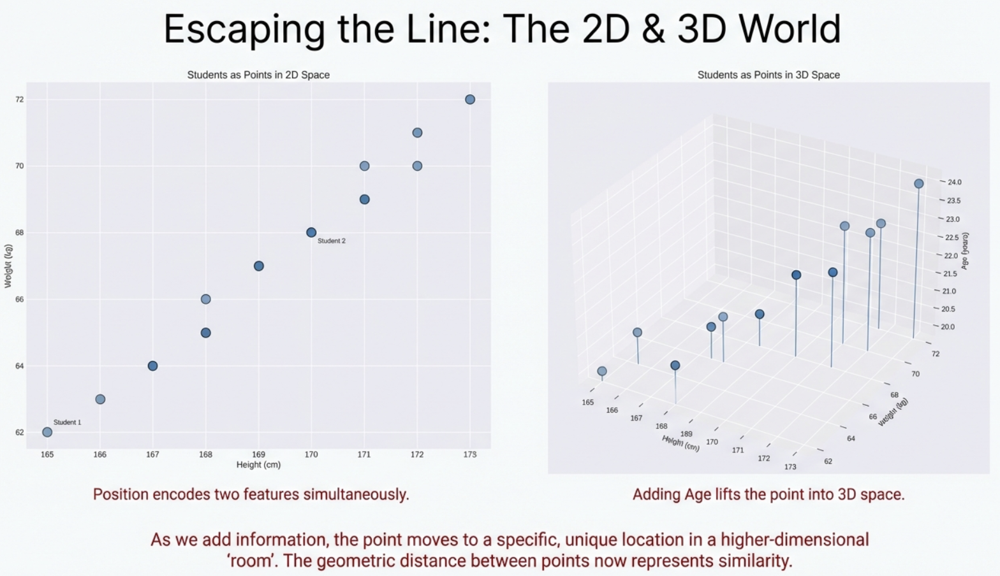

### Beyond Three Dimensions: The n-Dimensional World

What happens when we measure more features?

Imagine describing students with:
- Height
- Weight
- Age
- Hours of study per week
- Hours of sleep per night
- Distance from college (km)
- ... and so on

We can't visualize 6D or 10D space directly, but **mathematically, it works the same way**.

In [ ]:
# Creating a 5-dimensional dataset
n_students = 20
n_features = 5

# Each row is a student, each column is a feature
data_5d = np.column_stack([
    heights,
    weights,
    ages,
    np.random.randint(15, 35, n_students),  # study hours/week
    np.random.randint(5, 9, n_students)     # sleep hours/night
])

print(f"Shape of our dataset: {data_5d.shape}")
print(f"This means: {data_5d.shape[0]} students, {data_5d.shape[1]} features\n")
print("First 3 students:\n", data_5d[:3])
print("\nEach row represents one student in 5-dimensional space.")
print("Each student is a point with 5 coordinates.")

Shape of our dataset: (20, 5)
This means: 20 students, 5 features

First 3 students:
 [[165  62  20  21   7]
 [170  68  22  34   7]
 [168  65  21  29   7]]

Each row represents one student in 5-dimensional space.
Each student is a point with 5 coordinates.


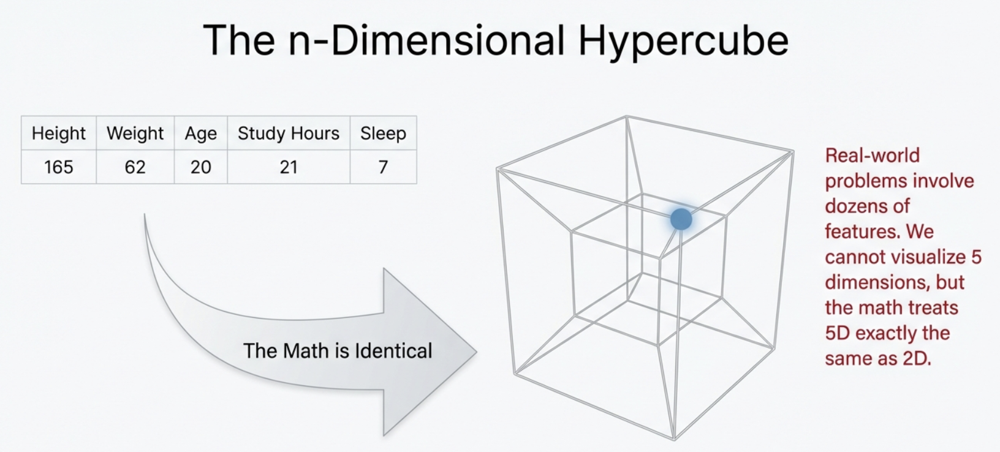

### Key Insight: The Geometry of Data

**In machine learning:**
- Each **data point** (student, fish, image) is a point in n-dimensional space
- Each **feature** (height, color, pixel value) is one dimension
- The **dataset** is a cloud of points in this space

This geometric view is fundamental to understanding ML:
- Classification = Drawing boundaries between point clusters
- Clustering = Finding groups of nearby points
- Dimensionality reduction = Projecting points onto fewer dimensions

But to work with these point clouds, we need to measure their properties. That's where **mean** and **variance** come in.

---

## Part 2: Finding the Center - The Mean

### What is the "Center" of Data?

Given a cloud of points, where is its center? Intuitively, it's the balance point—the location that best represents all points.

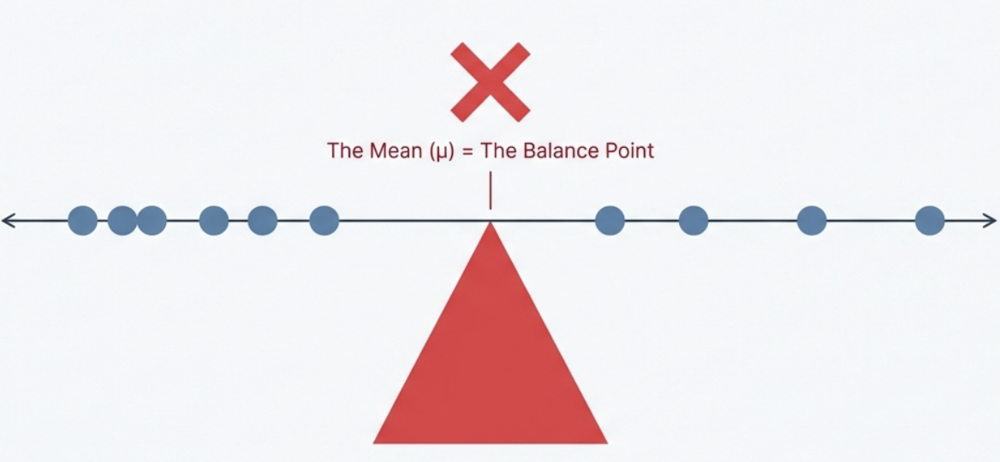

In [ ]:
# Let's work with heights again
print(f"Heights: {heights}")
print(f"\nMinimum height: {heights.min()} cm")
print(f"Maximum height: {heights.max()} cm")
print(f"\nWhat's the 'center' or 'typical' height?")

Heights: [165 170 168 172 169 171 167 173 170 166 169 171 168 170 172 167 169 171
 170 168]

Minimum height: 165 cm
Maximum height: 173 cm

What's the 'center' or 'typical' height?


The **mean** (average) is the arithmetic center:

$$\text{Mean} = \mu = \frac{1}{n} \sum_{i=1}^{n} x_i = \frac{x_1 + x_2 + ... + x_n}{n}$$

where:
- $n$ = number of data points
- $x_i$ = each individual data point
- $\mu$ (mu) = mean

In [ ]:
# Calculate mean manually
mean_height_manual = sum(heights) / len(heights)
print(f"Mean height (manual calculation): {mean_height_manual:.2f} cm")

# Using NumPy
mean_height = np.mean(heights)
print(f"Mean height (NumPy): {mean_height:.2f} cm")

Mean height (manual calculation): 169.30 cm
Mean height (NumPy): 169.30 cm


### Visualizing the Mean

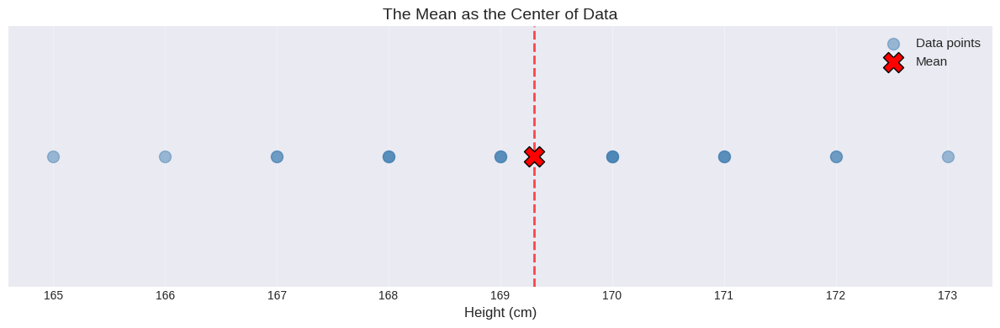


The mean (169.30 cm) is the balance point of the data.


In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))

# Plot data points
ax.scatter(heights, np.zeros_like(heights), s=100, alpha=0.5, c='steelblue', label='Data points')

# Plot mean
ax.scatter(mean_height, 0, s=300, c='red', marker='X', label='Mean', zorder=5, edgecolors='black')
ax.axvline(mean_height, color='red', linestyle='--', alpha=0.7, linewidth=2)

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_yticks([])
ax.set_title('The Mean as the Center of Data', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nThe mean ({mean_height:.2f} cm) is the balance point of the data.")

### Mean in 2D Space

When data has multiple features, we calculate the mean **for each dimension separately**.

In [ ]:
# Calculate mean for each feature
mean_height_2d = np.mean(heights)
mean_weight = np.mean(weights)

print(f"Mean height: {mean_height_2d:.2f} cm")
print(f"Mean weight: {mean_weight:.2f} kg")
print(f"\nThe center point: ({mean_height_2d:.2f}, {mean_weight:.2f})")

Mean height: 169.30 cm
Mean weight: 67.15 kg

The center point: (169.30, 67.15)


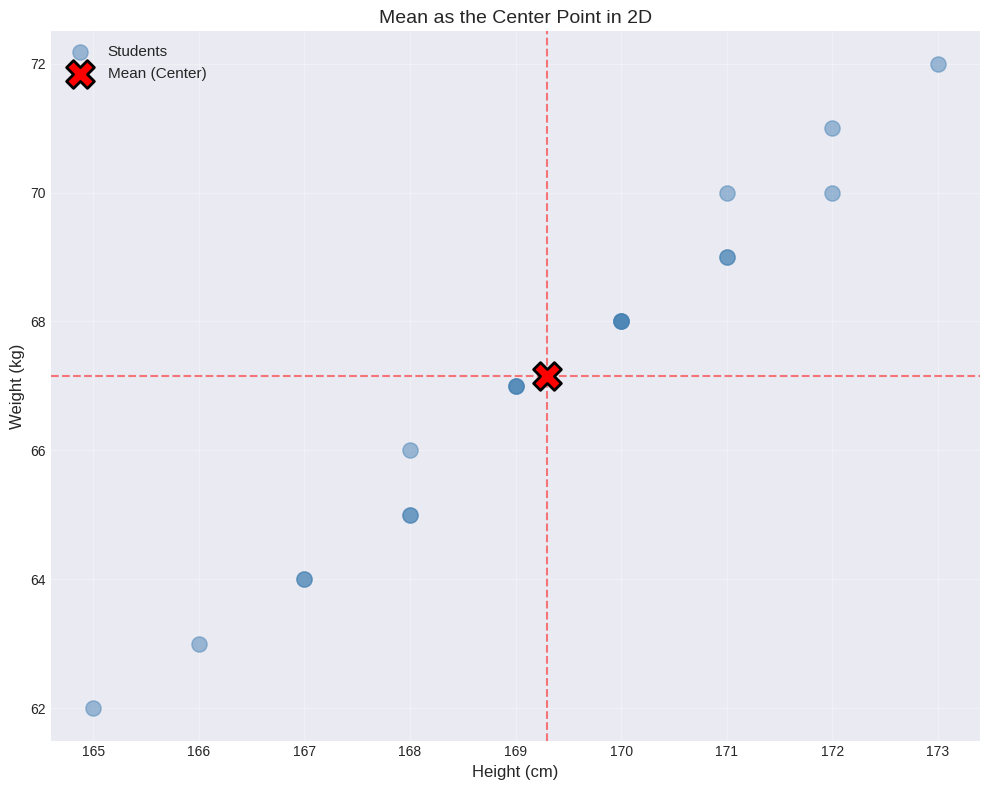


The mean point represents the 'average student' in this 2D space.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

# Plot data points
ax.scatter(heights, weights, s=120, alpha=0.5, c='steelblue', label='Students')

# Plot mean point
ax.scatter(mean_height_2d, mean_weight, s=400, c='red', marker='X',
           label='Mean (Center)', zorder=5, edgecolors='black', linewidths=2)

# Draw lines showing mean for each dimension
ax.axvline(mean_height_2d, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
ax.axhline(mean_weight, color='red', linestyle='--', alpha=0.5, linewidth=1.5)

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_title('Mean as the Center Point in 2D', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThe mean point represents the 'average student' in this 2D space.")

### Mean in Higher Dimensions

The concept extends naturally to any number of dimensions:

In [ ]:
# Mean for our 5D dataset
mean_5d = np.mean(data_5d, axis=0)  # axis=0 means calculate mean for each column

print("Mean values for each feature:")
feature_names = ['Height (cm)', 'Weight (kg)', 'Age (yrs)', 'Study (hrs/week)', 'Sleep (hrs/night)']
for i, (name, value) in enumerate(zip(feature_names, mean_5d)):
    print(f"  {name}: {value:.2f}")

print(f"\nThe mean is a single point in 5D space: {mean_5d}")
print("This point represents the 'center' or 'typical' student across all 5 dimensions.")

Mean values for each feature:
  Height (cm): 169.30
  Weight (kg): 67.15
  Age (yrs): 21.60
  Study (hrs/week): 23.40
  Sleep (hrs/night): 7.05

The mean is a single point in 5D space: [169.3   67.15  21.6   23.4    7.05]
This point represents the 'center' or 'typical' student across all 5 dimensions.


### Why the Mean Matters in ML

The mean is crucial because:
1. **Centering data**: Many ML algorithms work better when data is centered around zero
2. **Understanding clusters**: The mean helps identify where groups of data are located
3. **Detecting outliers**: Points far from the mean are unusual
4. **Normalization**: We often subtract the mean to standardize data

But the mean alone doesn't tell the full story. Two datasets can have the same mean but look completely different:

In [ ]:
# Two datasets with the same mean
data_tight = np.array([169, 170, 169, 170, 170, 169, 170, 171, 169, 170])
data_spread = np.array([150, 160, 165, 170, 170, 170, 175, 180, 185, 175])

print(f"Tight data mean: {np.mean(data_tight):.2f}")
print(f"Spread data mean: {np.mean(data_spread):.2f}")
print("\nBoth have the same mean! But are they really similar?")

Tight data mean: 169.70
Spread data mean: 170.00

Both have the same mean! But are they really similar?


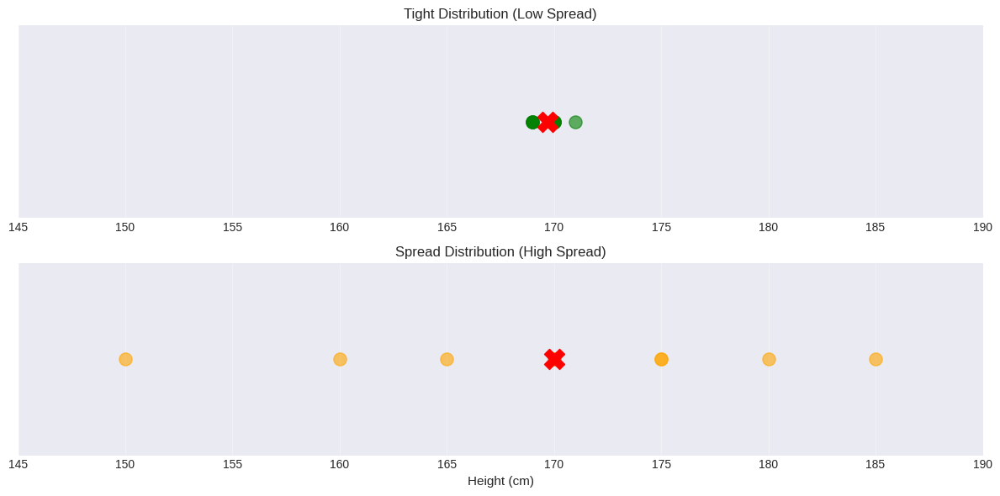


The mean is the same, but the SPREAD is different.
We need a way to measure this spread. Enter: VARIANCE.


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

# Tight data
axes[0].scatter(data_tight, np.zeros_like(data_tight), s=120, alpha=0.6, c='green')
axes[0].scatter(np.mean(data_tight), 0, s=300, c='red', marker='X', zorder=5)
axes[0].set_xlim(145, 190)
axes[0].set_title('Tight Distribution (Low Spread)', fontsize=12)
axes[0].set_yticks([])
axes[0].grid(True, axis='x', alpha=0.3)

# Spread data
axes[1].scatter(data_spread, np.zeros_like(data_spread), s=120, alpha=0.6, c='orange')
axes[1].scatter(np.mean(data_spread), 0, s=300, c='red', marker='X', zorder=5)
axes[1].set_xlim(145, 190)
axes[1].set_xlabel('Height (cm)', fontsize=11)
axes[1].set_title('Spread Distribution (High Spread)', fontsize=12)
axes[1].set_yticks([])
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThe mean is the same, but the SPREAD is different.")
print("We need a way to measure this spread. Enter: VARIANCE.")

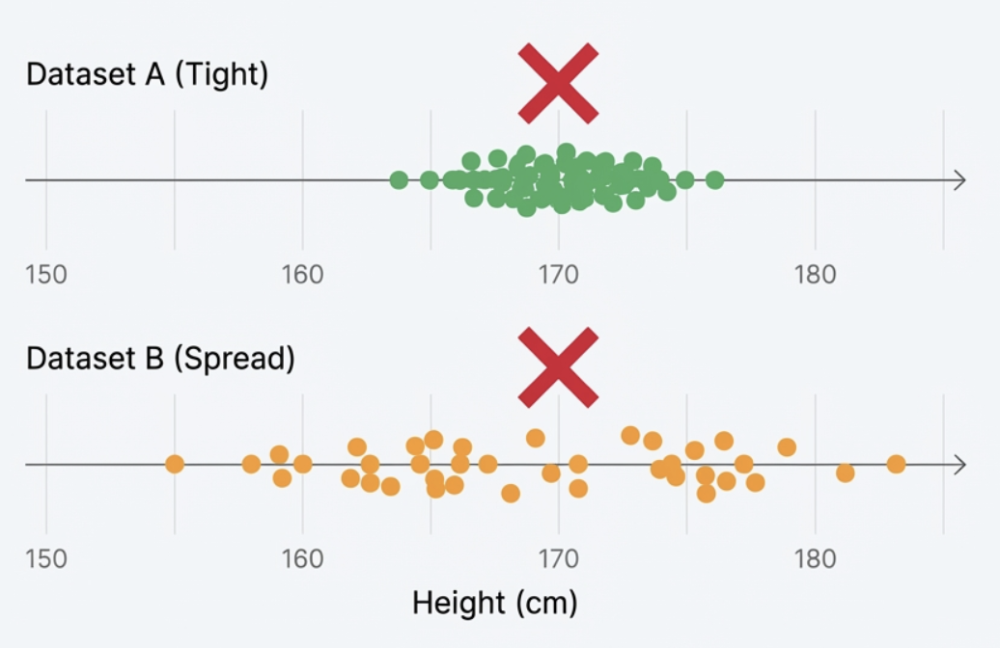

---

## Part 3: Measuring Spread - Variance and Standard Deviation

### The Intuition Behind Variance

Variance measures **how spread out** the data is from the mean.

Think about it this way:
- If all points are close to the mean → **Low variance** → Data is clustered
- If points are far from the mean → **High variance** → Data is spread out

### Building Variance Step by Step

**Step 1:** Find how far each point is from the mean

In [ ]:
# Using a small dataset for clarity
sample_heights = np.array([165, 170, 168, 172, 169])
sample_mean = np.mean(sample_heights)

print(f"Heights: {sample_heights}")
print(f"Mean: {sample_mean:.2f}\n")

# Calculate deviations from mean
deviations = sample_heights - sample_mean

print("Deviations from mean:")
for i, (height, dev) in enumerate(zip(sample_heights, deviations)):
    print(f"  Point {i+1}: {height} - {sample_mean:.2f} = {dev:+.2f}")

Heights: [165 170 168 172 169]
Mean: 168.80

Deviations from mean:
  Point 1: 165 - 168.80 = -3.80
  Point 2: 170 - 168.80 = +1.20
  Point 3: 168 - 168.80 = -0.80
  Point 4: 172 - 168.80 = +3.20
  Point 5: 169 - 168.80 = +0.20


**Step 2:** Why we can't just average the deviations

In [ ]:
sum_deviations = np.sum(deviations)
print(f"Sum of deviations: {sum_deviations:.6f}")
print("\nProblem: Positive and negative deviations cancel out!")
print("We always get zero (or very close to zero due to rounding).")
print("\nSolution: Square the deviations so all values become positive.")

Sum of deviations: -0.000000

Problem: Positive and negative deviations cancel out!
We always get zero (or very close to zero due to rounding).

Solution: Square the deviations so all values become positive.


**Step 3:** Square the deviations

In [ ]:
squared_deviations = deviations ** 2

print("Squared deviations:")
for i, (dev, sq_dev) in enumerate(zip(deviations, squared_deviations)):
    print(f"  Point {i+1}: ({dev:+.2f})² = {sq_dev:.2f}")

Squared deviations:
  Point 1: (-3.80)² = 14.44
  Point 2: (+1.20)² = 1.44
  Point 3: (-0.80)² = 0.64
  Point 4: (+3.20)² = 10.24
  Point 5: (+0.20)² = 0.04


**Step 4:** Calculate the variance

$$\text{Variance} = \sigma^2 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \mu)^2$$

where:
- $\sigma^2$ (sigma squared) = variance
- $x_i$ = each data point
- $\mu$ = mean
- $n$ = number of points

In [ ]:
# Calculate variance manually
variance_manual = np.sum(squared_deviations) / len(sample_heights)
print(f"Variance (manual): {variance_manual:.2f}")

# Using NumPy
variance_numpy = np.var(sample_heights)
print(f"Variance (NumPy): {variance_numpy:.2f}")

print(f"\nInterpretation: On average, each height deviates from the mean by {variance_manual:.2f} cm² (squared units).")

Variance (manual): 5.36
Variance (NumPy): 5.36

Interpretation: On average, each height deviates from the mean by 5.36 cm² (squared units).


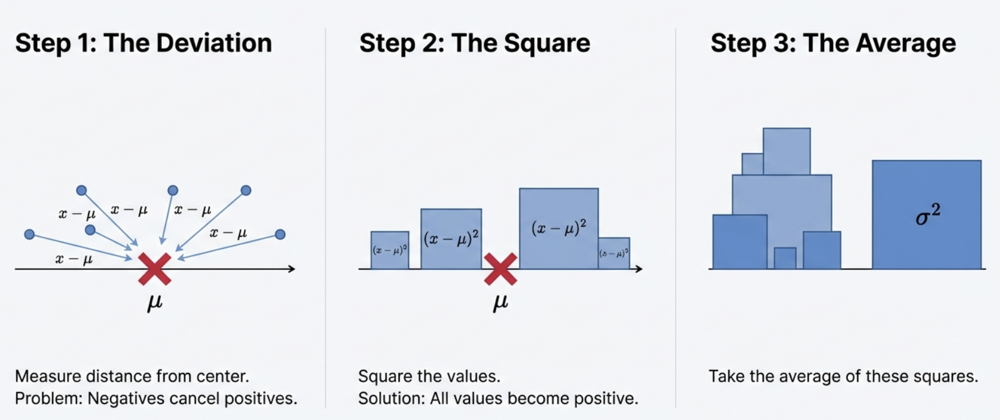

### Standard Deviation: Bringing Variance Back to Original Units

Variance is in **squared units** (cm², kg²), which is hard to interpret.

The **standard deviation** is simply the square root of variance:

$$\text{Standard Deviation} = \sigma = \sqrt{\text{Variance}} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (x_i - \mu)^2}$$

In [ ]:
# Calculate standard deviation
std_manual = np.sqrt(variance_manual)
std_numpy = np.std(sample_heights)

print(f"Standard deviation: {std_numpy:.2f} cm")
print(f"\nInterpretation: On average, heights deviate from the mean by about {std_numpy:.2f} cm.")
print("This is in the same units as our original data!")

Standard deviation: 2.32 cm

Interpretation: On average, heights deviate from the mean by about 2.32 cm.
This is in the same units as our original data!


### Visualizing Variance and Standard Deviation

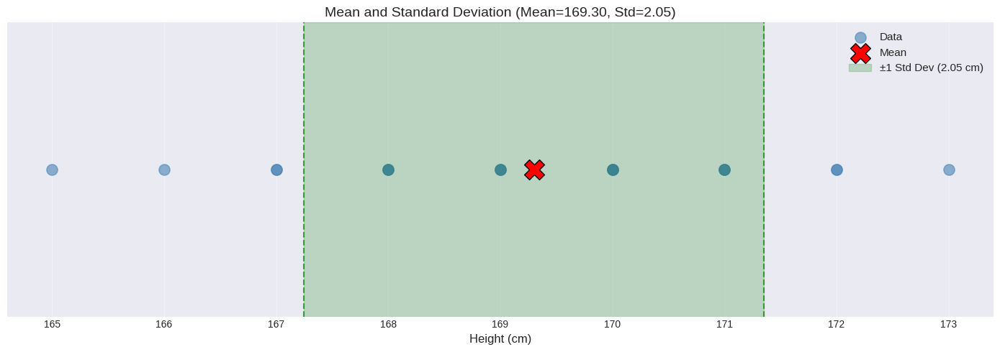


13 out of 20 points (65.0%) 
are within 1 standard deviation of the mean.


In [ ]:
# Back to our full dataset
mean_h = np.mean(heights)
std_h = np.std(heights)

fig, ax = plt.subplots(figsize=(14, 5))

# Plot data points
ax.scatter(heights, np.zeros_like(heights), s=120, alpha=0.6, c='steelblue', label='Data')

# Plot mean
ax.scatter(mean_h, 0, s=400, c='red', marker='X', label='Mean', zorder=5, edgecolors='black')

# Show standard deviation range
ax.axvspan(mean_h - std_h, mean_h + std_h, alpha=0.2, color='green',
           label=f'±1 Std Dev ({std_h:.2f} cm)')
ax.axvline(mean_h - std_h, color='green', linestyle='--', alpha=0.7)
ax.axvline(mean_h + std_h, color='green', linestyle='--', alpha=0.7)

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_yticks([])
ax.set_title(f'Mean and Standard Deviation (Mean={mean_h:.2f}, Std={std_h:.2f})', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Count points within 1 standard deviation
within_1std = np.sum(np.abs(heights - mean_h) <= std_h)
print(f"\n{within_1std} out of {len(heights)} points ({within_1std/len(heights)*100:.1f}%) ")
print(f"are within 1 standard deviation of the mean.")

### Comparing High vs Low Variance

In [ ]:
# Calculate variance for our earlier examples
var_tight = np.var(data_tight)
var_spread = np.var(data_spread)
std_tight = np.std(data_tight)
std_spread = np.std(data_spread)

print("Tight Distribution:")
print(f"  Variance: {var_tight:.2f} cm²")
print(f"  Std Dev: {std_tight:.2f} cm")
print("\nSpread Distribution:")
print(f"  Variance: {var_spread:.2f} cm²")
print(f"  Std Dev: {std_spread:.2f} cm")
print(f"\nThe spread distribution has {var_spread/var_tight:.1f}x more variance!")

Tight Distribution:
  Variance: 0.41 cm²
  Std Dev: 0.64 cm

Spread Distribution:
  Variance: 90.00 cm²
  Std Dev: 9.49 cm

The spread distribution has 219.5x more variance!


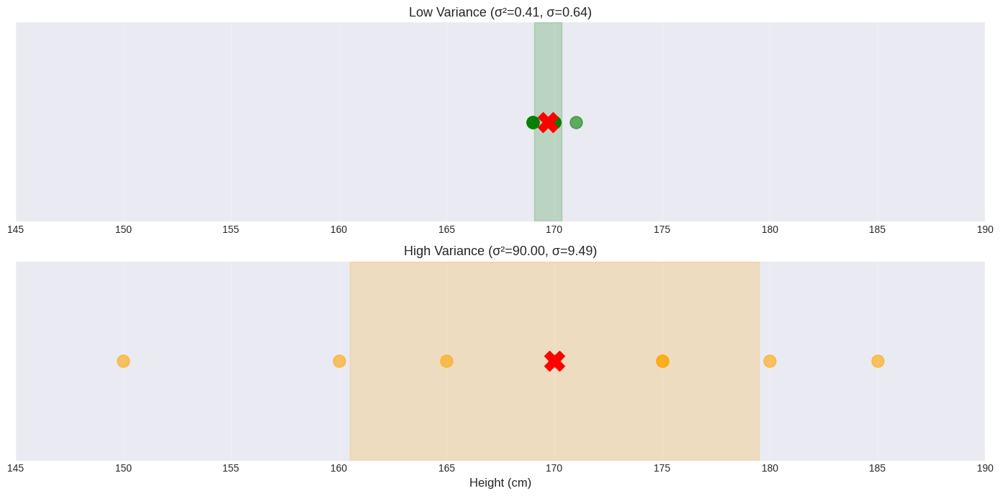


Key Observation:
Higher variance = Data is more spread out = More uncertainty = More diversity


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

mean_tight = np.mean(data_tight)
mean_spread = np.mean(data_spread)

# Tight distribution
axes[0].scatter(data_tight, np.zeros_like(data_tight), s=150, alpha=0.6, c='green')
axes[0].scatter(mean_tight, 0, s=400, c='red', marker='X', zorder=5)
axes[0].axvspan(mean_tight - std_tight, mean_tight + std_tight, alpha=0.2, color='green')
axes[0].set_xlim(145, 190)
axes[0].set_title(f'Low Variance (σ²={var_tight:.2f}, σ={std_tight:.2f})', fontsize=13)
axes[0].set_yticks([])
axes[0].grid(True, axis='x', alpha=0.3)

# Spread distribution
axes[1].scatter(data_spread, np.zeros_like(data_spread), s=150, alpha=0.6, c='orange')
axes[1].scatter(mean_spread, 0, s=400, c='red', marker='X', zorder=5)
axes[1].axvspan(mean_spread - std_spread, mean_spread + std_spread, alpha=0.2, color='orange')
axes[1].set_xlim(145, 190)
axes[1].set_xlabel('Height (cm)', fontsize=12)
axes[1].set_title(f'High Variance (σ²={var_spread:.2f}, σ={std_spread:.2f})', fontsize=13)
axes[1].set_yticks([])
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nKey Observation:")
print("Higher variance = Data is more spread out = More uncertainty = More diversity")

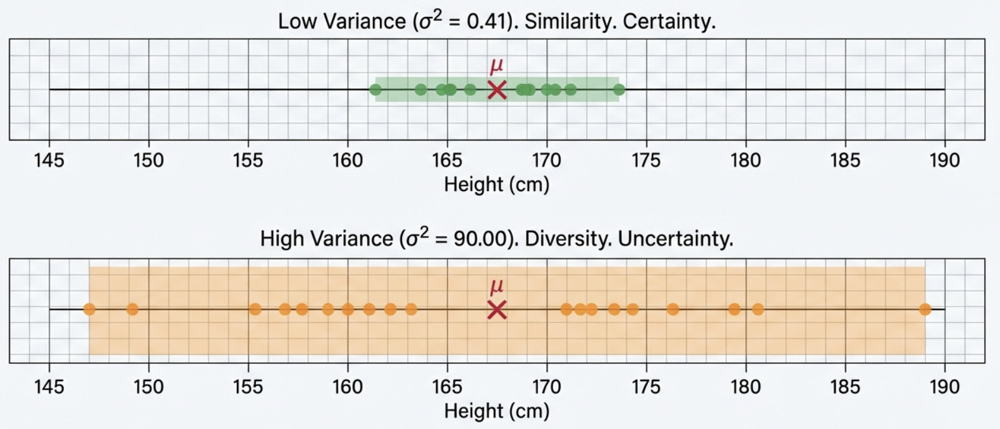

---

## Part 4: Sample vs Population

### The Complete Group vs A Sample

In statistics and ML, we distinguish between:

**Population**: The *entire* group we're interested in
- All students in a university
- All fish in the ocean
- All possible images of cats

**Sample**: A *subset* we actually measure
- 100 students from one class
- 500 fish caught in one location
- 10,000 cat images we downloaded

Usually, we only have access to a **sample**, but want to make conclusions about the **population**.

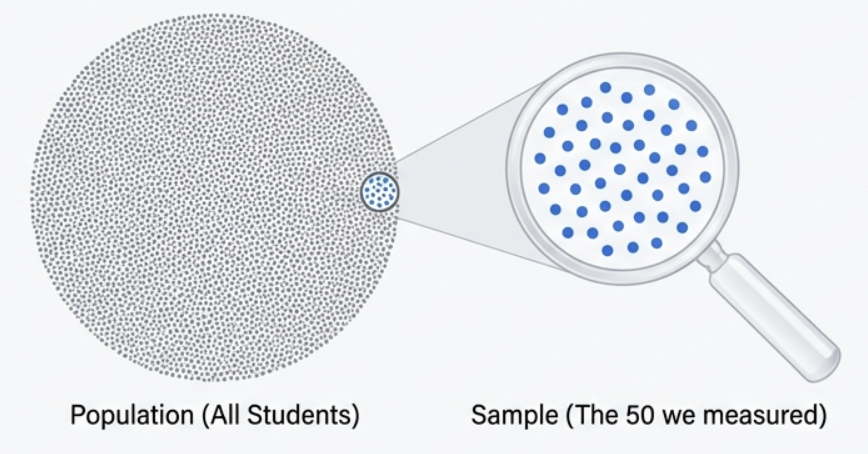

In [ ]:
# Simulate a population
np.random.seed(42)
population = np.random.normal(loc=170, scale=8, size=10000)  # 10,000 people

# Take a sample
sample = np.random.choice(population, size=50, replace=False)  # 50 people

print(f"Population size: {len(population)}")
print(f"Sample size: {len(sample)}")
print(f"\nPopulation mean: {np.mean(population):.2f}")
print(f"Sample mean: {np.mean(sample):.2f}")

Population size: 10000
Sample size: 50

Population mean: 169.98
Sample mean: 170.47


### Two Different Variance Formulas

When calculating variance:

**Population Variance** (we have ALL data):
$$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2$$

**Sample Variance** (we have only a sample):
$$s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2$$

Notice the denominator: $n-1$ instead of $n$.

**Why $n-1$?**
- Using $n$ tends to *underestimate* the population variance
- Dividing by $n-1$ corrects this bias
- This is called **Bessel's correction**
- For large samples, the difference is negligible

In [ ]:
# Population variance
pop_var = np.var(population, ddof=0)  # ddof=0 means divide by N
pop_std = np.std(population, ddof=0)

# Sample variance (unbiased)
sample_var_unbiased = np.var(sample, ddof=1)  # ddof=1 means divide by n-1
sample_std_unbiased = np.std(sample, ddof=1)

# Sample variance (biased)
sample_var_biased = np.var(sample, ddof=0)  # ddof=0 means divide by n

print("Population statistics:")
print(f"  Variance: {pop_var:.2f}")
print(f"  Std Dev: {pop_std:.2f}")
print("\nSample statistics (n-1 denominator, unbiased):")
print(f"  Variance: {sample_var_unbiased:.2f}")
print(f"  Std Dev: {sample_std_unbiased:.2f}")
print("\nSample statistics (n denominator, biased):")
print(f"  Variance: {sample_var_biased:.2f}")
print(f"\nThe unbiased estimate is closer to the true population variance.")

Population statistics:
  Variance: 64.44
  Std Dev: 8.03

Sample statistics (n-1 denominator, unbiased):
  Variance: 71.40
  Std Dev: 8.45

Sample statistics (n denominator, biased):
  Variance: 69.97

The unbiased estimate is closer to the true population variance.


### Practical Guideline

**In machine learning:**
- When you have the complete dataset → Use population formula (divide by $n$)
- When analyzing a sample to infer population properties → Use sample formula (divide by $n-1$)
- For large datasets, the difference is minimal
- **NumPy default**: `ddof=0` (population formula)
- **Pandas default**: `ddof=1` (sample formula)

Always check which formula your tools are using!

---

## Part 5: Variance as Information

### High Variance = More Information

Variance isn't just about spread—it tells us about **information content**.

Consider two features for classifying students:

In [ ]:
# Feature 1: Height (varies across students)
heights_class = np.array([165, 170, 168, 172, 169, 171, 167, 173, 170, 166,
                          169, 171, 168, 170, 172, 167, 169, 171, 170, 168])

# Feature 2: Number of eyes (constant for all students)
num_eyes = np.array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
                     2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

var_height = np.var(heights_class)
var_eyes = np.var(num_eyes)

print(f"Height variance: {var_height:.2f}")
print(f"Number of eyes variance: {var_eyes:.2f}")
print(f"\nWhich feature is more useful for distinguishing students?")

Height variance: 4.21
Number of eyes variance: 0.00

Which feature is more useful for distinguishing students?


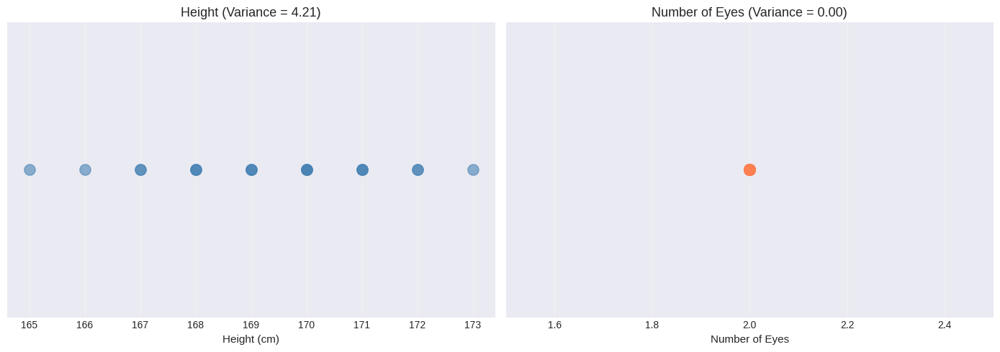


Insight: Zero variance = No information = Can't distinguish anything
High variance = Rich information = Can distinguish different cases


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Height (high variance)
axes[0].scatter(heights_class, np.zeros_like(heights_class), s=120, alpha=0.6, c='steelblue')
axes[0].set_xlabel('Height (cm)', fontsize=11)
axes[0].set_title(f'Height (Variance = {var_height:.2f})', fontsize=13)
axes[0].set_yticks([])
axes[0].grid(True, axis='x', alpha=0.3)

# Number of eyes (zero variance)
axes[1].scatter(num_eyes, np.zeros_like(num_eyes), s=120, alpha=0.6, c='coral')
axes[1].set_xlabel('Number of Eyes', fontsize=11)
axes[1].set_title(f'Number of Eyes (Variance = {var_eyes:.2f})', fontsize=13)
axes[1].set_yticks([])
axes[1].set_xlim([1.5, 2.5])
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nInsight: Zero variance = No information = Can't distinguish anything")
print("High variance = Rich information = Can distinguish different cases")

### Variance in Multiple Dimensions

When data has multiple features, we calculate variance **for each feature**:

In [ ]:
# Calculate variance for each feature in our 2D dataset
var_height_2d = np.var(heights)
var_weight_2d = np.var(weights)

print("Feature variances:")
print(f"  Height: {var_height_2d:.2f} cm²")
print(f"  Weight: {var_weight_2d:.2f} kg²")
print(f"\nWhich feature has more variation?")
if var_height_2d > var_weight_2d:
    print("Height varies more across students.")
else:
    print("Weight varies more across students.")

Feature variances:
  Height: 4.21 cm²
  Weight: 6.93 kg²

Which feature has more variation?
Weight varies more across students.


### Why This Matters in Machine Learning

**1. Feature Selection**: Features with zero or very low variance don't help classification

In [ ]:
# Example: Selecting informative features
feature_data = np.column_stack([
    heights_class,        # High variance
    num_eyes,             # Zero variance
    weights[:20]          # High variance
])

variances = np.var(feature_data, axis=0)
feature_names_ex = ['Height', 'Num_Eyes', 'Weight']

print("Feature variances:")
for name, var in zip(feature_names_ex, variances):
    print(f"  {name}: {var:.2f}")

# Remove low-variance features
variance_threshold = 1.0
informative_features = [name for name, var in zip(feature_names_ex, variances)
                       if var > variance_threshold]

print(f"\nInformative features (variance > {variance_threshold}): {informative_features}")
print("ML Insight: We can drop 'Num_Eyes' since it doesn't vary—it won't help classification!")

Feature variances:
  Height: 4.21
  Num_Eyes: 0.00
  Weight: 6.93

Informative features (variance > 1.0): ['Height', 'Weight']
ML Insight: We can drop 'Num_Eyes' since it doesn't vary—it won't help classification!


**2. Feature Scaling**: Features with very different variances can bias ML algorithms

In [ ]:
# Example with very different scales
income = np.array([30000, 45000, 52000, 38000, 60000, 35000, 48000, 55000])  # in dollars
age = np.array([25, 32, 28, 30, 35, 26, 29, 33])  # in years

print(f"Income variance: {np.var(income):.2f}")
print(f"Age variance: {np.var(age):.2f}")
print(f"\nIncome variance is {np.var(income)/np.var(age):.0f}x larger!")
print("\nMany ML algorithms will focus more on income simply because it has larger values.")
print("Solution: Standardize features to have similar variance (covered in future lectures).")

Income variance: 94484375.00
Age variance: 10.44

Income variance is 9052395x larger!

Many ML algorithms will focus more on income simply because it has larger values.
Solution: Standardize features to have similar variance (covered in future lectures).


---

## Part 6: Visualizing Clusters

### Variance Within Groups

In classification problems, we often have **labeled data**—points belonging to different classes.

Good classification happens when:
1. Points within each class are **close together** (low within-class variance)
2. Different classes are **far apart** (high between-class variance)

In [ ]:
# Create two distinct clusters
np.random.seed(42)

# Class A: Shorter, lighter students
class_a_height = np.random.normal(165, 3, 30)
class_a_weight = np.random.normal(58, 3, 30)

# Class B: Taller, heavier students
class_b_height = np.random.normal(175, 3, 30)
class_b_weight = np.random.normal(72, 3, 30)

print("Class A (Blue):")
print(f"  Mean height: {np.mean(class_a_height):.2f} cm")
print(f"  Mean weight: {np.mean(class_a_weight):.2f} kg")
print(f"  Height variance: {np.var(class_a_height):.2f}")

print("\nClass B (Orange):")
print(f"  Mean height: {np.mean(class_b_height):.2f} cm")
print(f"  Mean weight: {np.mean(class_b_weight):.2f} kg")
print(f"  Height variance: {np.var(class_b_height):.2f}")

Class A (Blue):
  Mean height: 164.44 cm
  Mean weight: 57.64 kg
  Height variance: 7.05

Class B (Orange):
  Mean height: 175.04 cm
  Mean weight: 71.94 kg
  Height variance: 8.56


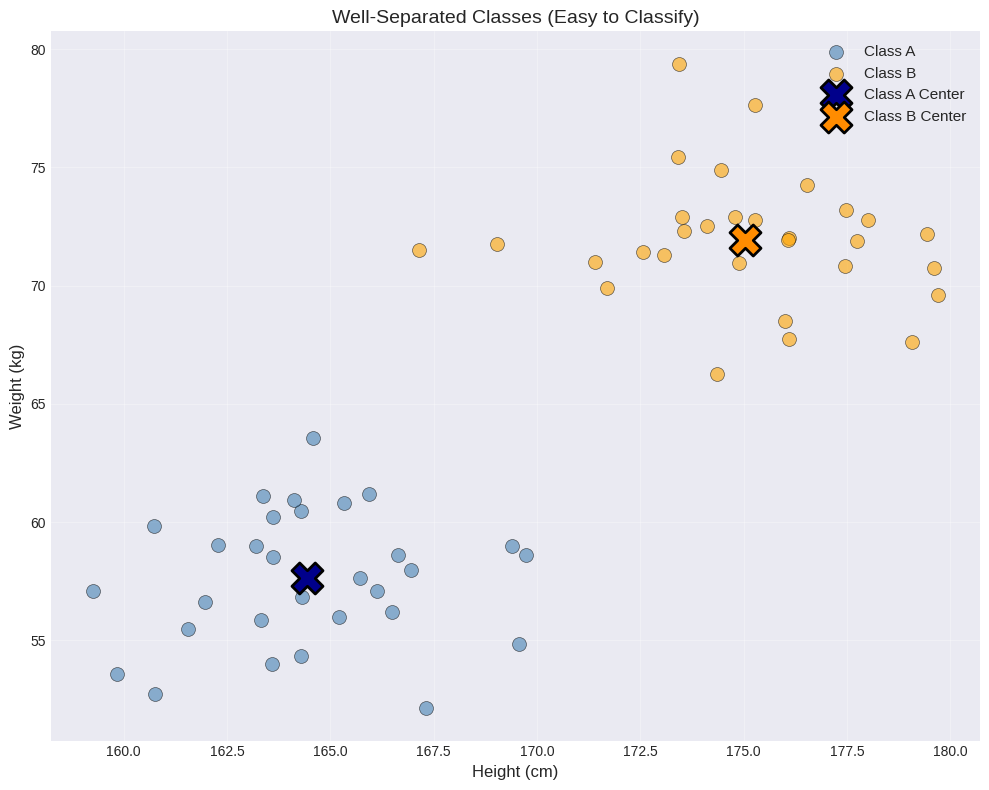


Observation: Classes are clearly separated. A line could easily divide them.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

# Plot both classes
ax.scatter(class_a_height, class_a_weight, s=100, alpha=0.6, c='steelblue',
           label='Class A', edgecolors='black', linewidths=0.5)
ax.scatter(class_b_height, class_b_weight, s=100, alpha=0.6, c='orange',
           label='Class B', edgecolors='black', linewidths=0.5)

# Plot class centers
ax.scatter(np.mean(class_a_height), np.mean(class_a_weight), s=500,
           c='darkblue', marker='X', edgecolors='black', linewidths=2, label='Class A Center')
ax.scatter(np.mean(class_b_height), np.mean(class_b_weight), s=500,
           c='darkorange', marker='X', edgecolors='black', linewidths=2, label='Class B Center')

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_title('Well-Separated Classes (Easy to Classify)', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nObservation: Classes are clearly separated. A line could easily divide them.")

### Overlapping Clusters: When Classification Becomes Hard

In [ ]:
# Create overlapping clusters (harder to separate)
np.random.seed(42)

# Class C: More spread out
class_c_height = np.random.normal(168, 6, 30)  # Higher variance
class_c_weight = np.random.normal(65, 6, 30)   # Higher variance

# Class D: Overlapping with C
class_d_height = np.random.normal(172, 6, 30)  # Closer mean, high variance
class_d_weight = np.random.normal(68, 6, 30)   # Closer mean, high variance

print("Class C:")
print(f"  Mean height: {np.mean(class_c_height):.2f} cm")
print(f"  Height variance: {np.var(class_c_height):.2f}")

print("\nClass D:")
print(f"  Mean height: {np.mean(class_d_height):.2f} cm")
print(f"  Height variance: {np.var(class_d_height):.2f}")

print("\nNotice: Higher variance within classes, closer class means.")

Class C:
  Mean height: 166.87 cm
  Height variance: 28.19

Class D:
  Mean height: 172.08 cm
  Height variance: 34.24

Notice: Higher variance within classes, closer class means.


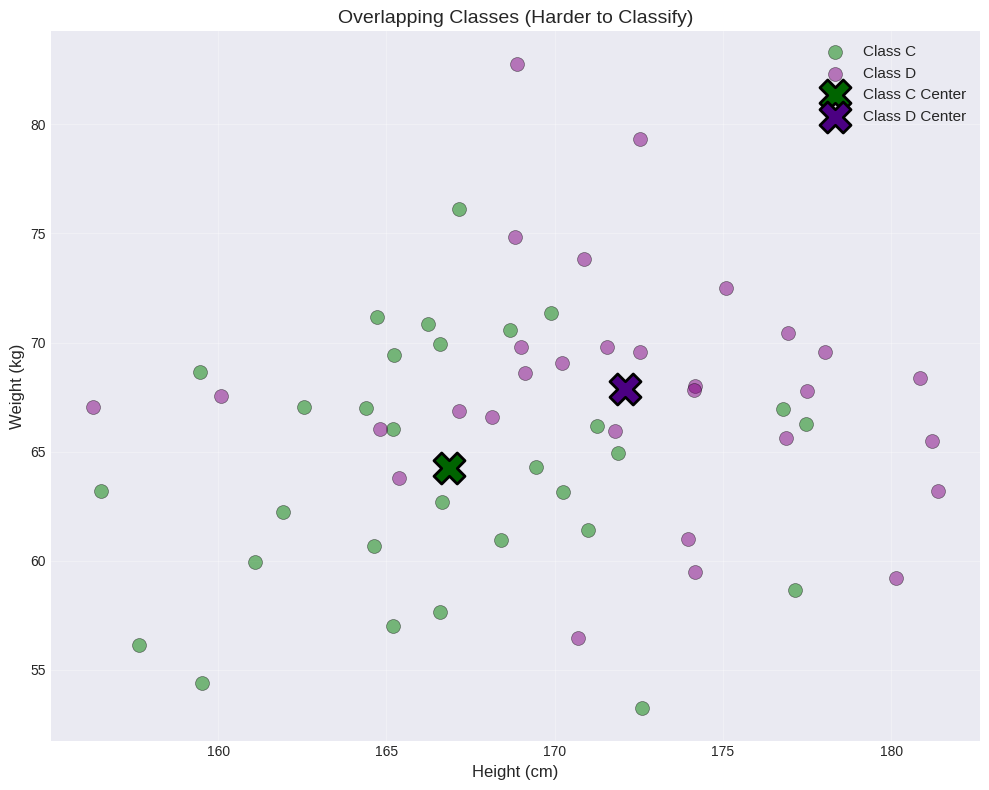


Observation: Classes overlap significantly. Much harder to draw a separating line.
This is where more sophisticated ML algorithms become necessary.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

# Plot overlapping classes
ax.scatter(class_c_height, class_c_weight, s=100, alpha=0.5, c='green',
           label='Class C', edgecolors='black', linewidths=0.5)
ax.scatter(class_d_height, class_d_weight, s=100, alpha=0.5, c='purple',
           label='Class D', edgecolors='black', linewidths=0.5)

# Plot class centers
ax.scatter(np.mean(class_c_height), np.mean(class_c_weight), s=500,
           c='darkgreen', marker='X', edgecolors='black', linewidths=2, label='Class C Center')
ax.scatter(np.mean(class_d_height), np.mean(class_d_weight), s=500,
           c='indigo', marker='X', edgecolors='black', linewidths=2, label='Class D Center')

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_title('Overlapping Classes (Harder to Classify)', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nObservation: Classes overlap significantly. Much harder to draw a separating line.")
print("This is where more sophisticated ML algorithms become necessary.")

### Quantifying Cluster Quality

We can measure how well-separated clusters are:

In [ ]:
# Well-separated clusters
distance_ab = np.sqrt((np.mean(class_a_height) - np.mean(class_b_height))**2 +
                      (np.mean(class_a_weight) - np.mean(class_b_weight))**2)
avg_variance_ab = (np.var(class_a_height) + np.var(class_b_height)) / 2

# Overlapping clusters
distance_cd = np.sqrt((np.mean(class_c_height) - np.mean(class_d_height))**2 +
                      (np.mean(class_c_weight) - np.mean(class_d_weight))**2)
avg_variance_cd = (np.var(class_c_height) + np.var(class_d_height)) / 2

print("Well-separated classes (A vs B):")
print(f"  Distance between centers: {distance_ab:.2f}")
print(f"  Average within-class variance: {avg_variance_ab:.2f}")
print(f"  Separation ratio: {distance_ab / np.sqrt(avg_variance_ab):.2f}")

print("\nOverlapping classes (C vs D):")
print(f"  Distance between centers: {distance_cd:.2f}")
print(f"  Average within-class variance: {avg_variance_cd:.2f}")
print(f"  Separation ratio: {distance_cd / np.sqrt(avg_variance_cd):.2f}")

print("\nHigher separation ratio = Better separated = Easier to classify")

Well-separated classes (A vs B):
  Distance between centers: 17.80
  Average within-class variance: 7.80
  Separation ratio: 6.37

Overlapping classes (C vs D):
  Distance between centers: 6.33
  Average within-class variance: 31.22
  Separation ratio: 1.13

Higher separation ratio = Better separated = Easier to classify


### Multiple Clusters: Real-World Complexity

Real datasets often have many classes forming complex patterns:

In [ ]:
# Create 4 different clusters (like 4 T-shirt sizes)
np.random.seed(42)

# Small
small_h = np.random.normal(160, 2.5, 25)
small_w = np.random.normal(55, 2.5, 25)

# Medium
medium_h = np.random.normal(168, 2.5, 25)
medium_w = np.random.normal(65, 2.5, 25)

# Large
large_h = np.random.normal(176, 2.5, 25)
large_w = np.random.normal(75, 2.5, 25)

# X-Large
xlarge_h = np.random.normal(184, 2.5, 25)
xlarge_w = np.random.normal(85, 2.5, 25)

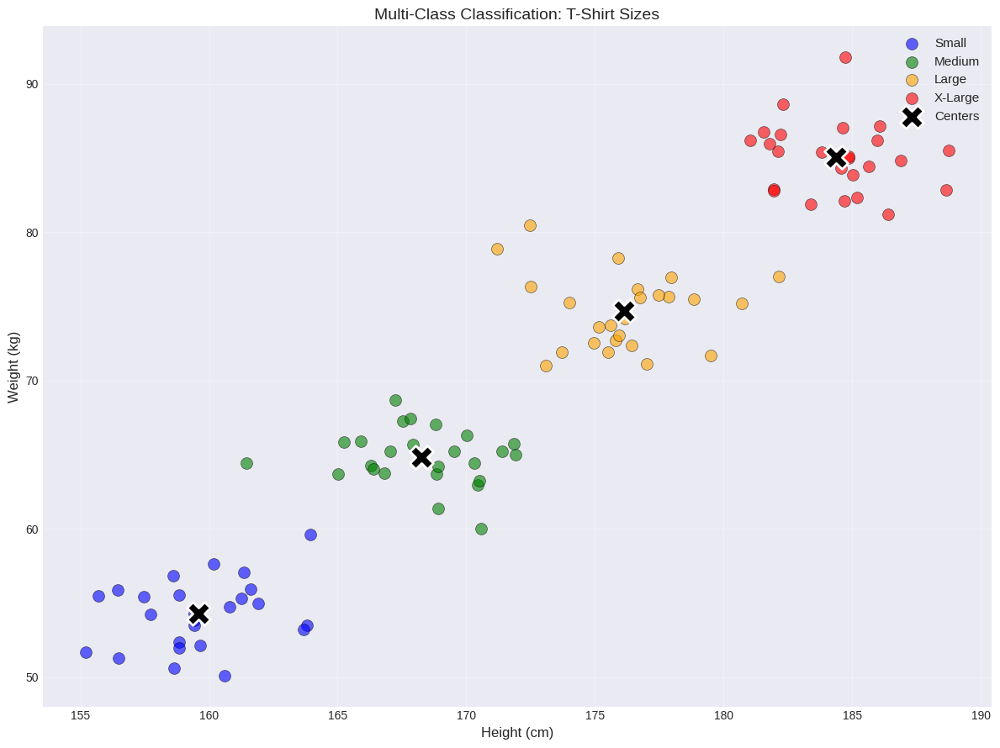


Real ML Challenge: Drawing boundaries between multiple classes.
Notice how clusters are organized along a diagonal trend.
This reveals correlation between height and weight—another key concept in ML!


In [ ]:
fig, ax = plt.subplots(figsize=(12, 9))

# Plot all clusters
ax.scatter(small_h, small_w, s=100, alpha=0.6, c='blue', label='Small', edgecolors='black', linewidths=0.5)
ax.scatter(medium_h, medium_w, s=100, alpha=0.6, c='green', label='Medium', edgecolors='black', linewidths=0.5)
ax.scatter(large_h, large_w, s=100, alpha=0.6, c='orange', label='Large', edgecolors='black', linewidths=0.5)
ax.scatter(xlarge_h, xlarge_w, s=100, alpha=0.6, c='red', label='X-Large', edgecolors='black', linewidths=0.5)

# Plot centers
centers_h = [np.mean(small_h), np.mean(medium_h), np.mean(large_h), np.mean(xlarge_h)]
centers_w = [np.mean(small_w), np.mean(medium_w), np.mean(large_w), np.mean(xlarge_w)]
ax.scatter(centers_h, centers_w, s=400, c='black', marker='X',
           edgecolors='white', linewidths=2, label='Centers', zorder=5)

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_title('Multi-Class Classification: T-Shirt Sizes', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nReal ML Challenge: Drawing boundaries between multiple classes.")
print("Notice how clusters are organized along a diagonal trend.")
print("This reveals correlation between height and weight—another key concept in ML!")

### Variance Analysis Across Clusters

In [ ]:
# Calculate within-cluster and between-cluster variance
all_heights = np.concatenate([small_h, medium_h, large_h, xlarge_h])
all_weights = np.concatenate([small_w, medium_w, large_w, xlarge_w])

# Total variance (treating all as one dataset)
total_var_h = np.var(all_heights)

# Average within-cluster variance
within_var_h = np.mean([np.var(small_h), np.var(medium_h), np.var(large_h), np.var(xlarge_h)])

# Between-cluster variance (variance of the means)
between_var_h = np.var(centers_h)

print("Height variance analysis:")
print(f"  Total variance: {total_var_h:.2f}")
print(f"  Within-cluster variance (avg): {within_var_h:.2f}")
print(f"  Between-cluster variance: {between_var_h:.2f}")
print(f"\nRatio between/within: {between_var_h/within_var_h:.2f}")
print("\nHigh ratio means clusters are well-separated relative to their internal spread.")
print("This makes classification much easier!")

Height variance analysis:
  Total variance: 89.98
  Within-cluster variance (avg): 5.53
  Between-cluster variance: 84.45

Ratio between/within: 15.27

High ratio means clusters are well-separated relative to their internal spread.
This makes classification much easier!


---

## Part 7: Connecting to Machine Learning

### The Big Picture

Everything we've learned today is foundational for ML:

**1. Geometric View**
- Data points live in n-dimensional space
- Each feature is one dimension
- ML algorithms operate on these geometric structures

**2. Mean**
- Represents the center of data
- Used for data centering/normalization
- Helps identify cluster centers in unsupervised learning

**3. Variance & Standard Deviation**
- Measures spread and information content
- Low variance features → Less useful for classification
- Used in feature scaling and selection
- Critical for understanding cluster quality

**4. Cluster Separation**
- Well-separated clusters → Easy classification
- Overlapping clusters → Need sophisticated algorithms
- Variance analysis reveals data structure

### Example: How Variance Guides ML Decisions

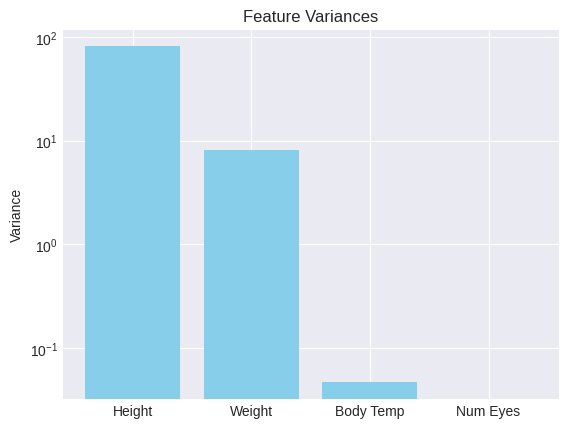

<Figure size 640x480 with 0 Axes>


ML Decision Making:
✓ Keep: Height, Weight (high/medium variance)
✗ Drop: Body Temp, Num Eyes (low/zero variance)

This is called 'Variance Threshold' feature selection!


In [ ]:
# Simulating a feature selection scenario
np.random.seed(42)

# Create features with different information content
n_samples = 100
feature_high_var = np.random.normal(170, 10, n_samples)      # Informative
feature_medium_var = np.random.normal(65, 3, n_samples)      # Somewhat informative
feature_low_var = np.random.normal(37.0, 0.2, n_samples)     # Almost useless (body temp)
feature_zero_var = np.full(n_samples, 2)                     # Completely useless (num eyes)

variances = [
    np.var(feature_high_var),
    np.var(feature_medium_var),
    np.var(feature_low_var),
    np.var(feature_zero_var)
]

feature_names_ml = ['Height', 'Weight', 'Body Temp', 'Num Eyes']

# Simple bar plot
plt.bar(feature_names_ml, variances, color='skyblue')
plt.ylabel('Variance')
plt.title('Feature Variances')
plt.yscale('log')  # keep log scale if needed
plt.show()

plt.tight_layout()
plt.show()

print("\nML Decision Making:")
print("✓ Keep: Height, Weight (high/medium variance)")
print("✗ Drop: Body Temp, Num Eyes (low/zero variance)")
print("\nThis is called 'Variance Threshold' feature selection!")

### Preview: What's Next

Building on today's foundations, upcoming lectures will cover:

1. **Covariance & Correlation**: How features relate to each other
2. **Distance Metrics**: Measuring similarity between points
3. **Linear Algebra**: Matrix operations for ML
4. **Optimization**: Finding the best decision boundaries
5. **Dimensionality Reduction**: Projecting high-D data to lower dimensions

All of these build directly on the geometric view and variance concepts we learned today.

---

## Summary & Key Takeaways

### Core Concepts

1. **Data as Geometry**
   - Each data point is a point in n-dimensional space
   - Each feature is one dimension
   - Datasets are clouds of points with structure

2. **Mean (μ)**
   - The arithmetic center of data: $\mu = \frac{1}{n}\sum_{i=1}^{n} x_i$
   - Calculated separately for each dimension
   - Represents the "typical" or "average" data point

3. **Variance (σ²)**
   - Measures spread around the mean: $\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \mu)^2$
   - Higher variance = more spread = more information
   - Zero variance = no information = useless for ML

4. **Standard Deviation (σ)**
   - Square root of variance: $\sigma = \sqrt{\sigma^2}$
   - In same units as original data
   - More interpretable than variance

5. **Sample vs Population**
   - Population: Entire dataset → divide by $n$
   - Sample: Subset to infer population → divide by $n-1$ (Bessel's correction)

6. **Cluster Quality**
   - Good separation = High between-class variance + Low within-class variance
   - Poor separation = Overlapping clusters
   - Variance ratios quantify separability

### ML Connections

- **Classification**: Drawing boundaries between point clusters
- **Feature Selection**: Removing low-variance features
- **Normalization**: Using mean and variance to scale data
- **Clustering**: Finding groups based on geometric proximity
- **Dimensionality Reduction**: Preserving variance in fewer dimensions

### Important Formulas

**Mean:**
$$\mu = \frac{1}{n}\sum_{i=1}^{n} x_i$$

**Population Variance:**
$$\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \mu)^2$$

**Sample Variance:**
$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

**Standard Deviation:**
$$\sigma = \sqrt{\sigma^2}$$

### Next Steps

You now understand how data exists geometrically and how to measure its central tendency and spread. Next lecture, we'll explore how features relate to each other through **covariance and correlation**, setting the stage for understanding linear models and decision boundaries.

---

**Remember**: Machine learning is fundamentally about finding patterns in geometric space. The concepts you learned today—points, centers, spread, and clusters—are the building blocks of every ML algorithm.